# PRIM — When Does Ambulance Pooling Hurt?

Find the parameter region where pooling ambulances **without** sharing facilities
(amb=1, fac=0) produces **higher** T1 mortality than full stovepiping (amb=0, fac=0).

Approach:
1. For each scenario (same seed + uncertainty combo), compare T1 mortality under
   policy (amb=1, fac=0) vs policy (amb=0, fac=0)
2. Mark scenarios where pooling made things worse (delta > 0)
3. Run PRIM on those flags to find the box

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
from ema_workbench.analysis import prim

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260604_195538_scenario_2btg_1ccp_each"  # <-- paste output folder name here
DAMAGE_THRESHOLD = 0.0   # delta > this means pooling hurt (0 = any increase)
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
print(f"Loaded {len(df)} runs")
print(f"Policies: {df[['facility_eligibility', 'ambulance_eligibility']].drop_duplicates().values.tolist()}")

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Loaded 2000 runs
Policies: [[0, 0], [1, 0], [0, 1], [1, 1]]


In [2]:
# ── Build scenario key (all uncertainty columns) ─────────────────────────────
UNCERTAINTIES = [c for c in ["seed", "ccp_r1_same_bn_min", "ccp_r1_inter_bn_min",
                             "bcas_rate", "waves_per_day", "wave_duration_min"] if c in df.columns]

# ── Split by policy ──────────────────────────────────────────────────────────
base = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].copy()
pool_amb = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].copy()

print(f"Stovepipe (fac=0, amb=0): {len(base)} runs")
print(f"Pool amb only (fac=0, amb=1): {len(pool_amb)} runs")

# ── Merge on scenario key ────────────────────────────────────────────────────
merged = base[UNCERTAINTIES + ["death_rate_T1_BCAS"]].merge(
    pool_amb[UNCERTAINTIES + ["death_rate_T1_BCAS"]],
    on=UNCERTAINTIES, suffixes=("_base", "_pool_amb")
)
merged["delta_t1"] = merged["death_rate_T1_BCAS_pool_amb"] - merged["death_rate_T1_BCAS_base"]

print(f"\nMatched scenarios: {len(merged)}")
print(f"Delta T1 mortality range: {merged['delta_t1'].min():.4f} to {merged['delta_t1'].max():.4f}")
print(f"Mean delta: {merged['delta_t1'].mean():.4f}")
print(f"Cases where pooling hurt: {(merged['delta_t1'] > DAMAGE_THRESHOLD).sum()} / {len(merged)} ({(merged['delta_t1'] > DAMAGE_THRESHOLD).mean():.1%})")

Stovepipe (fac=0, amb=0): 500 runs
Pool amb only (fac=0, amb=1): 500 runs

Matched scenarios: 500
Delta T1 mortality range: -1.0000 to 0.6667
Mean delta: -0.1086
Cases where pooling hurt: 143 / 500 (28.6%)


## PRIM — Under which conditions does ambulance pooling increase T1 mortality?

Cases of interest: 143 / 500 (28.6%)

Selected box:
coverage     0.230769
density      0.767442
id          26.000000
k           33.000000
mass         0.086000
mean         0.767442
n           43.000000
res_dim      5.000000
Name: 26, dtype: float64

                        box 26                                
                           min         max  qp value  qp value
ccp_r1_inter_bn_min  69.000000  144.500000  0.000004  0.250921
waves_per_day         3.500000    5.500000  0.015206  0.180361
ccp_r1_same_bn_min   11.500000   30.000000  0.105225       NaN
bcas_rate             0.019093    0.073336  0.250921  0.214775
wave_duration_min     5.500000  114.000000  0.250921  0.543331


[None]

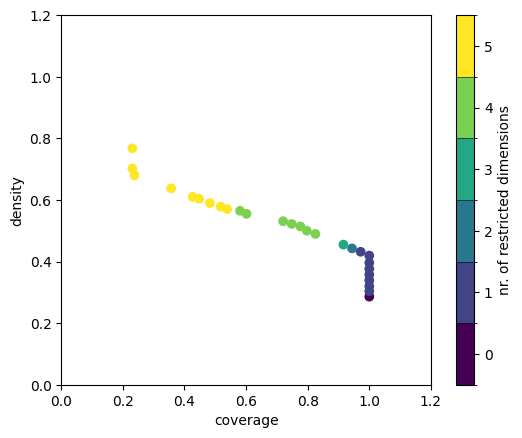

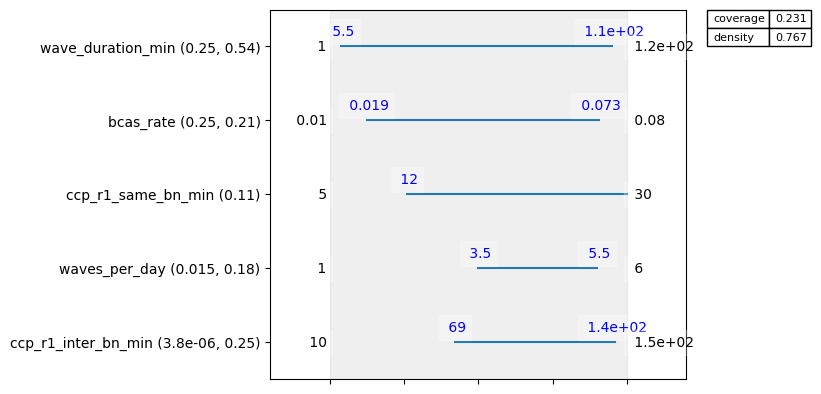

In [3]:
x_cols = [c for c in UNCERTAINTIES if c != "seed"]
x = merged[x_cols].astype(float)
y = merged["delta_t1"].values > DAMAGE_THRESHOLD

print(f"Cases of interest: {y.sum()} / {len(y)} ({y.mean():.1%})")

p = prim.Prim(x, y, threshold=0.5)
box = p.find_box()
box.show_tradeoff()
print("\nSelected box:")
box.inspect(style="graph")
box.inspect()

## Distribution of delta T1 mortality

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(x_cols), figsize=(5 * len(x_cols), 4))
for ax, col in zip(axes, x_cols):
    ax.scatter(merged[col], merged["delta_t1"], alpha=0.3, s=10)
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xlabel(col)
    ax.set_ylabel("Delta T1 mortality\n(pool_amb − stovepipe)")
    ax.set_title(col)
plt.suptitle("When does ambulance pooling (without facility sharing) hurt?", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()